# Lending Game — Part 10: Inferring the competitors' rules from Round 1

Part 9 showed that one Round 1 applicant in five was uncontested, and that this pool, not the
contested market, decided the ranking. Before improving our rule for Round 2 (Part 11), we need to
know **who** the competitors are and **what rules** produced that market.

**How the market is built** (course results, section A): for each loan, competitor slot 1 is one of
the **four type-1 teams** and slot 2 one of the **four type-2 teams** (three student teams and one
LLM team per type), each drawn at random. So the column `competing1` is not one lender but a
**mixture of four rules**, each applied to about a quarter of the applicants, and likewise for
`competing2`.

**What the guidelines ask, made precise:**

1. **Behaviours.** Each offer is a *no offer*, a *high quote* (90% or more, as in Part 9) or a
   *curve* offer (a rate that depends on risk). Measure their shares by risk band.
2. **Split each slot into its four teams.** The guidelines suggest clustering on the margin. The
   offers carry stronger fingerprints than the margin: the number of decimals each team rounded
   to, a fixed high quote, and "charm" rates ending in 9. A team is drawn for a quarter of the
   applicants, so counting each fingerprint in **teams' worth** per risk band recovers the teams.
3. **Each team's rule:**
   * the implied **margin curve**: the regression of the rate on `p_own` and the competitor's
     reconstructed default probability, and binned margins;
   * the **probability of no offer** as a function of risk, and the risk at which the high-quote
     teams switch to their high quote.
4. **The empirical Round 2 scenario:** competitor offers resampled from the real Round 1 offers,
   given the risk band, with knobs to stress each behaviour (Part 11).

**The competitors' default probability is never observed:** we do not see `signal1` or `signal2`.
`p_hat1` and `p_hat2` are its forecast from our own information (Part 6's competitor model, fitted on
the past loans, as for rule R7). It is an expectation, so it is compressed (it rarely exceeds 30%),
and every competitor "threshold" below is blurred by the signal we cannot see.

The code is in `src/round_1_competitors_rules.py`.

## 0. Setup

In [1]:
import sys
sys.path.append("..")  # make src/ importable from analysis/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.config import FIGURES_DIR
from src.pricing_rules import load_pricing_data, load_tuned_rules
from src.round_1_replay import rule_high_quote, rule_switch, score_replay
from src import model_plots as mp
from src import pricing_plots as pp

from src import round_1_competitors_rules as crr

mp.set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def save(fig, name):
    # Save a figure for the Part 10 report.
    fig.savefig(FIGURES_DIR / name, dpi=150, bbox_inches="tight")


train = load_pricing_data("train")
data = crr.load_round1_competitors(train)
print(f"{len(data):,} Round 1 applicants")
display(data[["r1", "r2", "r3_submitted", "pref", "default", "p_own", "p_public", "p_hat1", "p_hat2"]]
        .head())
display(data[["p_own", "p_hat1", "p_hat2"]].describe(percentiles=[.5, .9, .99]).T
        .style.format("{:.4f}").format("{:,.0f}", subset=["count"]))

100,000 Round 1 applicants


,r1,r2,r3_submitted,pref,default,p_own,p_public,p_hat1,p_hat2
id,,,,,,,,,
1,0.039284,0.0559,0.041016,3,0,0.022548,0.022196,0.021265,0.021425
2,NaN,NaN,0.120825,1,1,0.081860,0.100561,0.097757,0.098384
3,0.043756,0.0739,0.041385,3,0,0.022856,0.022461,0.021479,0.021652
4,0.115800,NaN,0.128803,3,0,0.088536,0.118094,0.113273,0.113839
5,0.159800,NaN,0.316272,1,0,0.128557,0.155296,0.151557,0.153128


,count,mean,std,min,50%,90%,99%,max
p_own,"100,000",0.0996,0.0774,0.0001,0.0867,0.2045,0.3369,0.5020
p_hat1,"100,000",0.0970,0.0685,0.0001,0.0886,0.1731,0.2605,0.2981
p_hat2,"100,000",0.0972,0.0686,0.0001,0.0889,0.1737,0.2595,0.2982


## 1. Three behaviours

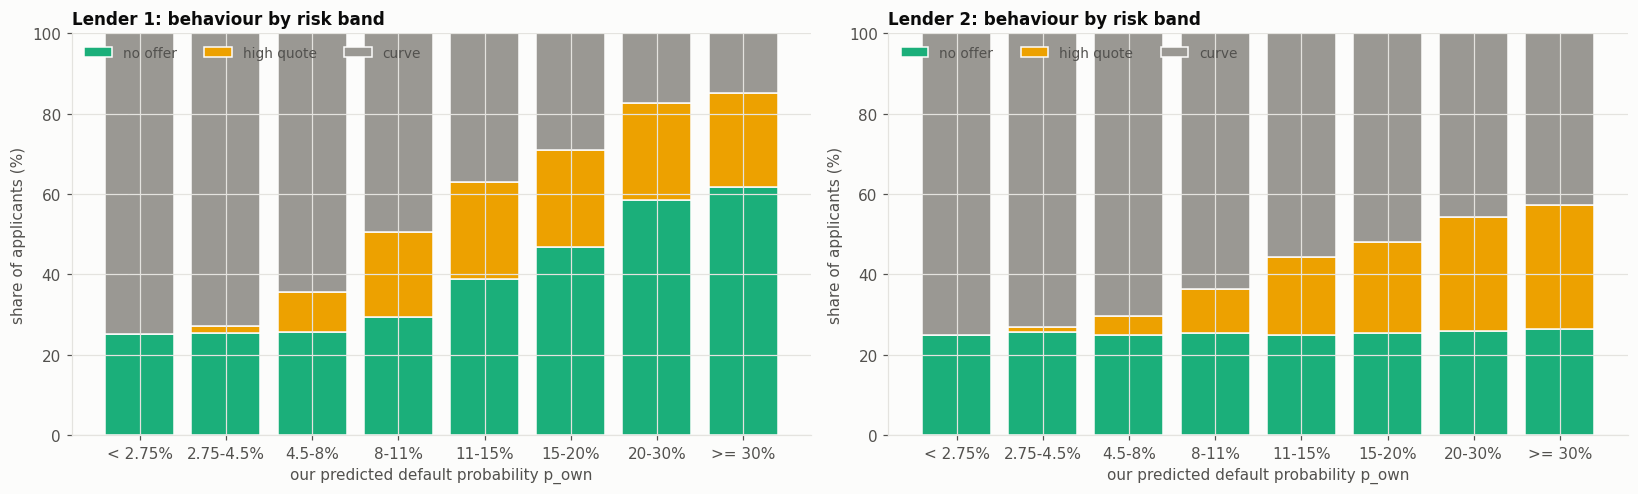

,no offer,high quote,curve
lender 1,34.4%,14.2%,51.4%
lender 2,25.2%,11.5%,63.3%


In [2]:
shares = crr.behaviour_shares(data)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
crr.plot_behaviour_shares(shares, axes)
fig.tight_layout()
save(fig, "fig22_competitor_behaviours.png")
plt.show()

overall = pd.DataFrame({f"lender {k}": crr.behaviour(data, k).value_counts(normalize=True)
                        .reindex(crr.BEHAVIOURS) for k in crr.LENDERS}).T
display(overall.style.format("{:.1%}"))
display(shares.style.format("{:.1%}"))

**Both slots mix the same three behaviours, in very different proportions by risk:**

* **No offer.** Lender 2: **25.2%**, flat at 25% in every risk band. Lender 1: **34.4%**, 25% for the
  safest applicants and rising to 62% above 30% risk.
* **High quote** (90% or more). Almost nothing below 4.5% risk. It then rises to **24% of all
  applicants for lender 1** (from 11% risk) and **31% for lender 2** (above 30% risk).
* **Curve offers** fall from 75% of the safest applicants to 15% (lender 1) and 43% (lender 2) of
  the riskiest.

Two numbers stand out: **25%** and **24–25%**. A quarter is exactly one team out of four. The next
section checks whether each behaviour is one team's.

## 2. Fingerprints: telling the four teams apart

In [3]:
# How many decimals did each offer have when the team submitted it?
dec = pd.DataFrame({f"lender {k}": crr.decimals(data[f"r{k}"]).value_counts().sort_index()
                    for k in crr.LENDERS}).fillna(0).astype(int)
dec.index = dec.index.astype(int).rename("decimals")
display(dec.T)

# Lender 2's 4-decimal offers: the last decimal (fixed quote 97.89% excluded).
r2 = data["r2"]
four = (crr.decimals(r2) <= 4) & ~np.isclose(r2.fillna(-1), crr.FIXED_QUOTES[2], atol=1e-6)
last = (np.round(r2[four] * 1e4).astype(int) % 10).value_counts().sort_index()
display(last.rename("lender 2, 4-decimal offers").to_frame().T)

groups = pd.DataFrame({f"lender {k}": crr.fingerprint(data, k).value_counts().reindex(crr.GROUPS[k])
                       for k in crr.LENDERS})
display(groups.fillna(0).astype(int).T)

decimals,1,2,3,4,5,6,7,8,9
lender 1,11,154,1534,31271,3062,29582,0,0,0
lender 2,38,169,2320,47479,62,585,5733,12942,5481


,0,1,2,3,4,5,6,7,8,9
"lender 2, 4-decimal offers",2527,1909,2236,3059,2404,2168,2290,2946,2588,17352


,4-decimal curve,6-decimal curve,charm curve (ends in 9),fixed quote 91.99%,fixed quote 97.89%,full-precision curve,no offer
lender 1,18756,32644,0,14214,0,0,34386
lender 2,22127,0,17352,0,10527,24803,25191


**The offers carry the teams' fingerprints.**

* **Decimals.** The course file stores rates as float32, so `0.0559` is read back as
  `0.055900000`. The number of decimals a team actually submitted is the fewest decimals that give
  the same float32 (`decimals`).
  * Lender 1's offers have either **at most 4 decimals** or **5–6 decimals**: two kinds of teams.
  * Lender 2's offers have either **at most 4 decimals** or **5–9** (mostly 7–9): a team that does
    not round.
* **Fixed quotes.** 91.99% (lender 1, 14,214 offers) and 97.89% (lender 2, 10,527 offers): one rate,
  whatever the risk.
* **Charm pricing.** Among lender 2's 4-decimal offers, **17,352 end in 9**, against about 2,400
  for each other digit (0.0199, 0.0249, …). The fixed quote 97.89% ends in 9 too. One team prices
  just below round numbers, and it is the high-quote team. About 14% of the offers ending in 9
  (~2,450, the share any other digit gets) come from the other 4-decimal team by chance.

Each slot's offers therefore fall into fingerprint groups:

| lender 1 | lender 2 |
|---|---|
| no offer | no offer |
| fixed quote 91.99% | fixed quote 97.89% |
| 6-decimal curve | charm curve (ends in 9) |
| 4-decimal curve | 4-decimal curve |
| | full-precision curve |

**Counting in teams' worth.** Within a risk band of $n$ applicants, each team is drawn for about
$n/4$ of them. Dividing each group's count by $n/4$ gives how many teams it represents. A group at
**1.00 in every band** is one team that always behaves that way. A group that falls from 1 to 0 is
a team that stops offering, or switches behaviour, as risk rises. Each row sums to 4. The bands are
those of the competitor's own predicted risk $\hat p_k$.

lender 1: fingerprint groups in teams' worth, by band of p_hat1


group1,no offer,fixed quote 91.99%,6-decimal curve,4-decimal curve
p_hat1,,,,
< 2%,1.01,0.00,1.98,1.00
2-4%,1.01,0.02,1.95,1.03
4-6%,1.01,0.15,1.83,1.01
6-8%,1.00,0.46,1.51,1.03
8-10%,1.12,0.75,1.22,0.91
10-12%,1.20,0.99,0.98,0.83
12-15%,1.49,1.03,0.90,0.58
15-20%,1.83,1.00,0.79,0.37
>= 20%,2.84,0.90,0.25,0.00


lender 2: fingerprint groups in teams' worth, by band of p_hat2


group2,no offer,fixed quote 97.89%,charm curve (ends in 9),4-decimal curve,full-precision curve
p_hat2,,,,,
< 2%,0.98,0.00,1.10,0.88,1.04
2-4%,1.01,0.02,1.11,0.85,1.01
4-6%,1.03,0.07,1.03,0.91,0.96
6-8%,0.99,0.21,0.90,0.89,1.01
8-10%,1.01,0.36,0.77,0.87,0.98
10-12%,1.01,0.50,0.60,0.90,0.99
12-15%,0.99,0.69,0.43,0.89,0.99
15-20%,1.00,0.92,0.21,0.88,0.99
>= 20%,1.08,0.99,0.12,0.91,0.91


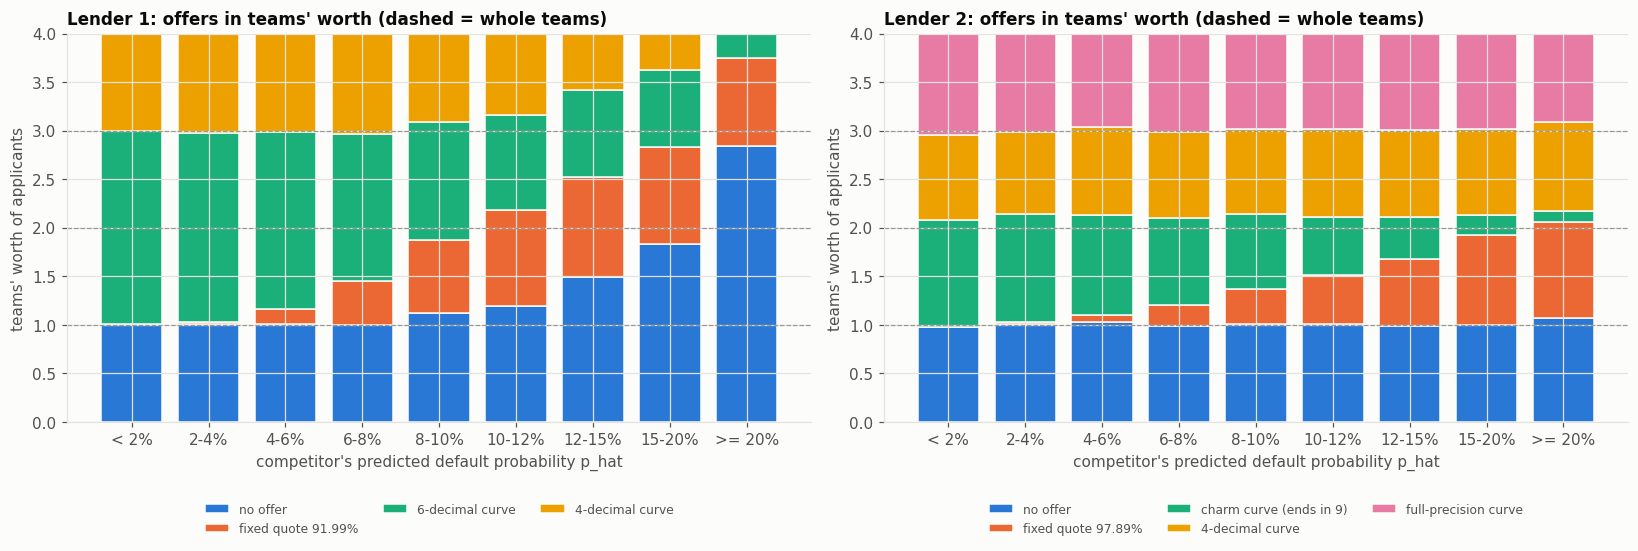

In [4]:
units = {k: crr.team_units(data, k) for k in crr.LENDERS}
for k in crr.LENDERS:
    print(f"lender {k}: fingerprint groups in teams' worth, by band of p_hat{k}")
    display(units[k].style.format("{:.2f}"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, k in zip(axes, crr.LENDERS):
    crr.plot_team_units(units[k], ax, f"Lender {k}: offers in teams' worth (dashed = whole teams)")
fig.tight_layout()
save(fig, "fig23_competitor_teams.png")
plt.show()

**Lender 2 splits into four teams almost exactly:**

* **No offer = 1.00 team in every band** (0.98–1.08). **One type-2 team never makes an offer**,
  whatever the risk. Its no-offers are unrelated to the borrower's type and the application id,
  and barely related to the default (25.1% for borrowers who repaid, 26.1% for those who defaulted;
  next cell).
* **Full-precision curve = 1.00 team in every band** (0.91–1.04): a team that offers to everyone.
* **Charm curve + fixed quote 97.89% = 1.1 teams in every band**: one team plus the ~0.1 team of
  look-alike 9s. It offers a curve to safe applicants and moves to 97.89% as risk rises.
* **4-decimal curve ≈ 0.9 team in every band** (+ the 0.1 in the charm group): a team that offers
  to everyone.

**Lender 1 also has four teams:**

* **No offer = 1.00 team below 8% risk:** again, **one type-1 team never offers**. Above 8%, the
  no-offers grow to 1.2, 1.5, 1.8 and then 2.8 teams: **other teams start refusing risky applicants**.
* **Fixed quote 91.99%** rises from 0 to **1.00 team** from 10% risk. Below that, this team's offers
  are **6-decimal curve** offers: the 6-decimal group is **2 teams** for safe applicants and falls to
  1 team as the high-quote team switches.
* So the **6-decimal curve** is two teams on safe applicants: the high-quote team's curve, and a
  second team that offers to 0.98, 0.90, 0.79 and finally 0.25 team's worth from 10% risk upwards.
  It refuses more and more risky applicants.
* **4-decimal curve = 1.00 team below 8% risk**, then 0.91, 0.83, 0.58, 0.37 and **0**: a team with
  a **no-offer cutoff** that refuses everyone above about 20% predicted risk.

The two never-offer teams are surprising, since the league table lists a positive profit for every
team. They may be teams whose Round 1 submission was not read for our market. Either way, in our
market **one draw in four, in each slot, made no offer at all**, and nothing says it will stay that
way in Round 2.

In [5]:
# Lender 2's no-offers: are they related to anything? (one team that never offers: no)
no2 = data["r2"].isna()
id_decile = pd.Series(pd.qcut(data.index, 10, labels=False), index=data.index)
display(pd.concat({"by default": no2.groupby(data["default"]).mean(),
                   "by borrower type": no2.groupby(data["pref"]).mean(),
                   "by id decile": no2.groupby(id_decile).mean()}).to_frame("no offer, lender 2")
        .T.style.format("{:.1%}"))

## 3. The rules of each team

### 3.1 The high-quote switch and the no-offers

In [6]:
fits, ys = {}, {}
for k in crr.LENDERS:
    fits[f"lender {k}: no offer"] = crr.fit_no_offer(data, k)
    ys[f"lender {k}: no offer"] = data[f"r{k}"].isna()
    fits[f"lender {k}: fixed quote {crr.FIXED_QUOTES[k]:.2%}"] = crr.fit_high_quote(data, k)
    ys[f"lender {k}: fixed quote {crr.FIXED_QUOTES[k]:.2%}"] = np.isclose(
        data[f"r{k}"].fillna(-1), crr.FIXED_QUOTES[k], atol=1e-6)

table = crr.share_curve_table(fits)
display(table.style.format({"floor": "{:.1%}", "ceiling": "{:.1%}", "floor (teams)": "{:.2f}",
                            "ceiling (teams)": "{:.2f}", "midpoint": "{:.1%}", "a": "{:.2f}",
                            "b": "{:.2f}"}))

checks = {name: crr.observed_vs_fitted(data, int(name.split()[1].rstrip(":")), fits[name], ys[name])
          for name in fits}
display(pd.concat(checks, axis=1).style.format("{:.1%}"))

,floor,ceiling,floor (teams),ceiling (teams),midpoint,a,b
lender 1: no offer,24.9%,86.8%,1.00,3.47,19.4%,4.89,3.43
lender 1: fixed quote 91.99%,0.0%,25.0%,0.00,1.00,7.1%,12.82,4.98
lender 2: no offer,25.1%,27.0%,1.00,1.08,21.4%,12204.78,9383.22
lender 2: fixed quote 97.89%,0.0%,25.0%,0.00,1.00,10.4%,7.06,3.28


**The model.** A plain logistic curve cannot have a floor at 25% (a team that never offers) or a
ceiling at 25% (one team in four quoting high). So each share is fitted by maximum likelihood as

$$P(\text{behaviour} \mid \hat p_k) = \text{floor} + (\text{ceiling} - \text{floor})\cdot
\text{expit}\big(a + b\,\text{logit}\,\hat p_k\big),$$

with the floor and ceiling estimated for the no-offers and fixed at 0 and 1/4 for the fixed quotes.
The **midpoint** $\text{expit}(-a/b)$ is the risk at which half of the switching teams have switched.

* **Lender 1, no offer:** floor **25% (1.00 team)**, ceiling **87% (3.5 teams)**, midpoint
  **$\hat p_1 = 19\%$**. That is the never-offer team, plus two to three teams whose refusals start
  around 10% risk and become the rule above 20%: the 4-decimal team, the second 6-decimal team, and a
  few no-offers from the high-quote team at the very top.
* **Lender 2, no offer:** **flat at 25%**: the floor and ceiling coincide (1.00 and 1.08 teams). No
  type-2 team refuses on risk; the slope is not identified and means nothing.
* **Lender 1's high-quote team** switches to 91.99% at **$\hat p_1 \approx 7\%$**, and quotes it to
  all its applicants from 10%.
* **Lender 2's high-quote team** switches to 97.89% at **$\hat p_2 \approx 10\%$**, more gradually.

These thresholds are on **our forecast** of the competitor's risk. The team itself switches on its
own estimate, which uses a signal we do not see, so its real rule is sharper than these curves.
Read 7% and 10% as "the competitor's predicted default risk, around which the switch happens".

### 3.2 The margin curves

lender 1: median margin r - be(p_hat1) of curve offers (points), by band of p_hat1


p_hat1,< 2%,2-4%,4-6%,6-8%,8-10%,10-12%,12-15%,15-20%,>= 20%
group1,,,,,,,,,
6-decimal curve,1.7,1.5,2.4,2.9,6.0,7.7,9.8,8.9,8.6
4-decimal curve,1.4,1.9,2.9,4.5,5.3,5.0,3.5,1.3,-6.7


p_hat1,< 2%,2-4%,4-6%,6-8%,8-10%,10-12%,12-15%,15-20%,>= 20%
group1,,,,,,,,,
6-decimal curve,7003,6125,4969,3405,2446,2000,2559,3677,460
4-decimal curve,3544,3224,2750,2332,1824,1703,1637,1737,5


lender 2: median margin r - be(p_hat2) of curve offers (points), by band of p_hat2


p_hat2,< 2%,2-4%,4-6%,6-8%,8-10%,10-12%,12-15%,15-20%,>= 20%
group2,,,,,,,,,
charm curve (ends in 9),2.1,2.5,3.0,2.9,2.9,2.3,2.0,0.1,28.0
4-decimal curve,3.0,2.8,3.2,3.8,4.9,5.7,7.2,9.8,20.4
full-precision curve,2.3,2.3,2.6,5.1,5.0,34.9,36.9,37.3,45.2


p_hat2,< 2%,2-4%,4-6%,6-8%,8-10%,10-12%,12-15%,15-20%,>= 20%
group2,,,,,,,,,
charm curve (ends in 9),3870,3486,2790,2018,1548,1211,1235,979,193
4-decimal curve,3096,2660,2462,2004,1750,1826,2519,3915,1197
full-precision curve,3659,3178,2607,2275,1973,1999,2827,4468,1571


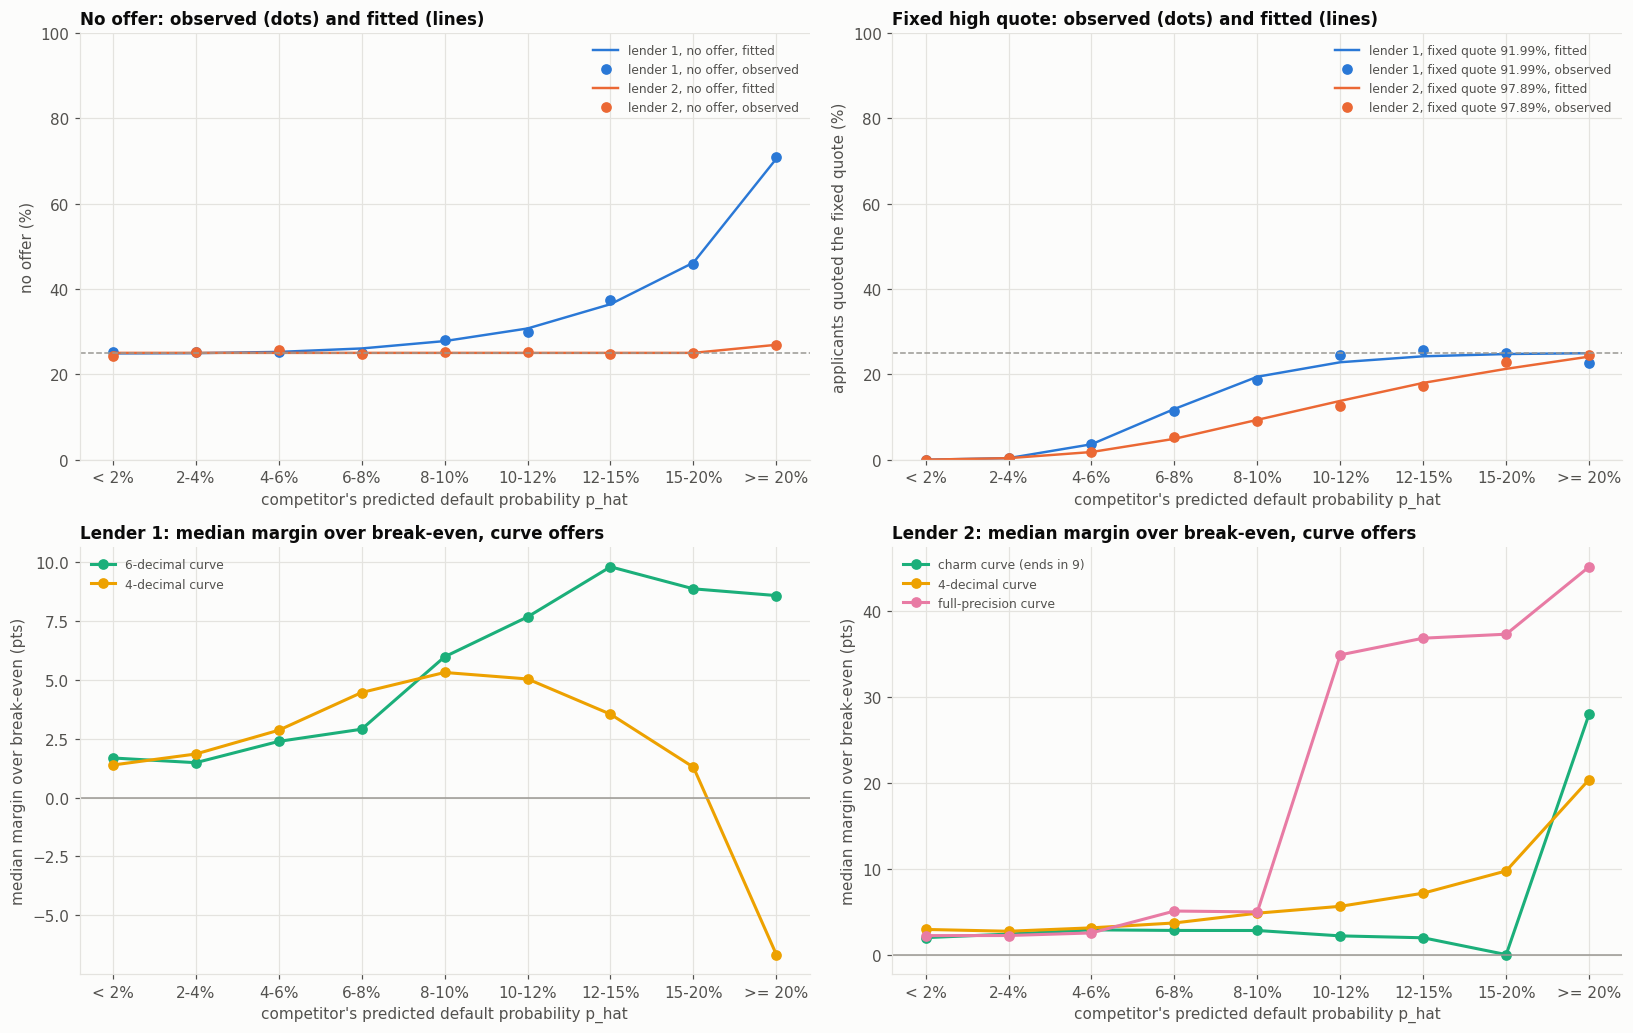

In [7]:
medians = {k: crr.margin_table(data, k) for k in crr.LENDERS}
counts = {k: crr.margin_table(data, k, stat="n") for k in crr.LENDERS}
for k in crr.LENDERS:
    print(f"lender {k}: median margin r - be(p_hat{k}) of curve offers (points), by band of p_hat{k}")
    display((100 * medians[k]).style.format("{:.1f}"))
    display(counts[k])

regressions = pd.concat({f"lender {k}": crr.margin_regression(data, k) for k in crr.LENDERS})
display(regressions.style.format({"offers": "{:,.0f}", "a (intercept)": "{:.3f}",
                                  "b (be of p_hat)": "{:.2f}", "c (be of p_own)": "{:.2f}",
                                  "b + c": "{:.2f}", "R2": "{:.2f}", "median p_hat": "{:.1%}",
                                  "margin at median p_hat": "{:.1%}"}))

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
crr.plot_share_curves({name.replace(": ", ", "): checks[name] for name in checks if "no offer" in name},
                      axes[0, 0], "No offer: observed (dots) and fitted (lines)", "no offer (%)")
crr.plot_share_curves({name.replace(": ", ", "): checks[name] for name in checks if "fixed" in name},
                      axes[0, 1], "Fixed high quote: observed (dots) and fitted (lines)",
                      "applicants quoted the fixed quote (%)")
for ax, k in zip(axes[1], crr.LENDERS):
    crr.plot_margin_curves(medians[k], ax, f"Lender {k}: median margin over break-even, curve offers")
fig.tight_layout()
save(fig, "fig24_competitor_rules.png")
plt.show()

**Margins.** For curve offers only (no offers and offers of 90% or more left out), the implied margin
is $r - be(\hat p_k)$: how far above the competitor's predicted break-even it priced. It is noisy for
one applicant, because the competitor's real $p$ differs from our forecast by its signal, but its
median by band is the team's margin curve.

* **Lender 1, 4-decimal team:** **1.4 points** for the safest, rising to **4.5–5.3 points** around 6–12%
  risk, then lower as it stops offering (it keeps only the applicants its signal says are safe).
* **Lender 1, 6-decimal teams:** **1.5–3 points** below 8% risk (two teams mixed). Above 10%, where only
  the second 6-decimal team is left, **8–10 points**.
* **Lender 2, charm team:** **2–3 points** wherever it still offers a curve, then 97.89%.
* **Lender 2, 4-decimal team:** a margin that **rises steadily with risk**: 3 points for the safest, 5
  around 9%, 7–10 points at 12–20% and 20 points above.
* **Lender 2, full-precision team:** a **step**. About **2.3 points below 6% risk**, about **5 points**
  at 6–10%, then **35–45 points** above 10%. It quotes the risky applicants high but below 90%, like
  our R4 with a bigger step.

**The guideline's regression**, $r = a + b\,be(\hat p_k) + c\,be(p_{own})$ on each group's curve offers:

* **$c \approx 0$ for every group.** Once the competitor's predicted risk is in, our `p_own` adds
  nothing: the competitors price on their own information, as they should. $\hat p_k$ already
  contains everything in `p_own` that predicts their $p$.
* **$b + c$ (pass-through of risk into the rate)** is 1.04 for lender 1's 4-decimal team (a constant
  margin of about 2.8 points over break-even), 1.3 for the charm team, 1.4–1.5 for the 6-decimal and
  4-decimal teams (margins that grow with risk), and **2.7 for the full-precision team** (the step).
* $R^2$ = 0.7–0.8: the remaining spread is mostly the competitors' signals, which we cannot see.

The regression summarises each group's level and slope. The binned medians show the shape, which is
not linear for the teams with a step or a cutoff.

### 3.3 The eight competitor teams

| slot | team | fingerprint | rule (in terms of the competitor's risk $\hat p$) |
|---|---|---|---|
| lender 1 | **1A** | no offer | **never offers** |
| | **1B** | 6-decimal curve, then 91.99% | about 2 points over break-even; **91.99% from $\hat p \approx 7\%$**, for everyone from 10% |
| | **1C** | 6-decimal curve | about 2 points over break-even on safe applicants, **8–10 points above 10%**; refuses more and more above 15% (a quarter of its applicants left above 20%) |
| | **1D** | 4-decimal curve | **1.4 → 5 points** as risk rises; **no offer above about 20%** (falls from 1 team at 8% to 0 above 20%) |
| lender 2 | **2A** | no offer | **never offers** |
| | **2B** | charm rates (…9), then 97.89% | **2–3 points** over break-even; **97.89% from $\hat p \approx 10\%$** |
| | **2C** | 4-decimal curve | offers to everyone; margin **rising from 3 to 20 points** with risk |
| | **2D** | full precision | offers to everyone; **about 2.3 points below 6%, 35–45 points above 10%** (a step) |

**What this means for us.**

* **Every competitor team is aggressive on safe applicants**: 1.4–3 points over its break-even. This
  is close to our R4 margins (1.75–3.2 points). Safe applicants are contested by three teams in each
  slot.
* **The uncontested pool has three sources:**
  1. the two **never-offer teams** (1A, 2A), which leave **1/4 × 1/4 = 6.25%** of applicants with no
     competitor offer at all, whatever their risk;
  2. the two **high-quote teams** (1B, 2B), which switch to 91.99% / 97.89% above 7–10% risk;
  3. the **cutoff teams** of lender 1 (1C, 1D), which refuse risky applicants.

## 4. How the competitors did against us in Round 1

In [8]:
results = crr.competitor_results(data)
display(results.style.format({"applicants": "{:,}", "offers": "{:,}", "loans won": "{:,.0f}",
                              "win rate": "{:.1%}", "avg rate won": "{:.1%}",
                              "default rate won": "{:.1%}", "profit": "{:+,.0f}",
                              "profit per loan": "{:+,.0f}"}))

Against our submitted R4 offers, with the real borrower types:

* **The high-quote teams won almost nothing:** 29 loans at 91.99% and 21 at 97.89%. Their quotes are
  not meant to win. In practice they **hand the applicant to whoever quotes below them**, and in
  Round 1 that was us, at R4's 30–50%.
* **The curve teams won 40–45% of the applicants they offered to**, at an average rate of 11–17%,
  and earned **€270–350 per loan**, half of R4's €630.
* **Lender 2's full-precision team (2D) won only 22%** of its offers. Its 35–45-point step on risky
  applicants rarely beats R4's 17–19 points.

These are the profits of each competitor *in our market only*: the league table adds up each team's
loans across all sixteen competitor pairings.

## 5. Where the uncontested applicants come from

In [9]:
sources = crr.uncontested_sources(data)
display(sources.style.format("{:.2f}"))

,no competitor offer,if independent,both never-offer teams,only high quotes,if independent
p_own,,,,,
< 2.75%,6.27,6.24,6.25,0.02,0.03
2.75-4.5%,6.49,6.55,6.25,0.88,0.76
4.5-8%,6.80,6.37,6.25,4.36,4.14
8-11%,7.38,7.48,6.25,11.42,10.91
11-15%,9.49,9.71,6.25,18.61,18.15
15-20%,12.21,11.86,6.25,22.48,22.18
20-30%,15.25,15.14,6.25,30.61,29.66
>= 30%,16.15,16.31,6.25,33.24,32.43


In % of the applicants of each band of `p_own`:

* **No competitor offer:** **6.3% for the safest applicants, exactly the 1/16 = 6.25%** of
  applicants for whom both slots drew their never-offer team. It rises to 16% for the riskiest,
  through lender 1's cutoff teams.
* **Only high quotes:** almost zero below 4.5% risk, then 4%, 11%, 19%, 22%, 31% and 33% as the
  high-quote teams switch.
* **The two slots refuse independently:** the observed shares match the product of each slot's rates
  within a fraction of a point. Given `p_own`, knowing that lender 1 refused says almost nothing
  about lender 2.

**This is the key fact for Round 2.** Part 9 found that a high quote on *safe* applicants is the
most robust part of the gain (R8|R4). Those safe uncontested applicants exist **only because two
teams made no offer at all**. If either never-offer team starts quoting in Round 2, the safe
uncontested pool disappears. The risky pool depends on the high-quote and cutoff teams, which are
real pricing choices and more likely to persist.

## 6. The empirical Round 2 scenario

In [10]:
# Our rules on the Round 1 applicants (as in Part 9).
rules = load_tuned_rules(train)
edges = rules["R4"].params["edges"]
r4 = rules["R4"](data)
rates = {
    "R4": r4,
    "R4+C": rules["R4+C"](data),
    "R8 flat (89.5%)": rule_high_quote(data, 0.895),
    "R4|R8 11.1%": rule_switch(data, r4, edges[5], 0.895, "above"),
    "R8|R4 6.4%": rule_switch(data, r4, edges[3], 0.895, "below"),
    "R8|R4 11.1%": rule_switch(data, r4, edges[5], 0.895, "below"),
}
actual = score_replay(rates, data)[0]["profit"]

SEEDS = range(10)
check_mean, check_sd = crr.score_scenarios(
    rates, data, data, {"empirical": {}, "without the default": {"use_default": False},
                        "empirical, 10 risk bins": {"n_bins": 10}}, seeds=SEEDS)
check = pd.DataFrame({"Round 1 (real offers)": actual,
                      "empirical": check_mean["empirical"],
                      "sd over draws": check_sd["empirical"],
                      "empirical, 10 risk bins": check_mean["empirical, 10 risk bins"],
                      "without conditioning on the default": check_mean["without the default"]})
display((check / 1e6).style.format("{:+.1f}").format("{:.2f}", subset=["sd over draws"]))

,Round 1 (real offers),empirical,sd over draws,"empirical, 10 risk bins",without conditioning on the default
rule,,,,,
R4,+35.0,+35.2,0.72,+34.6,+42.5
R4+C,+9.3,+9.5,0.36,+9.5,+11.9
R8 flat (89.5%),+118.9,+118.9,1.39,+118.5,+125.2
R4|R8 11.1%,+77.5,+77.5,1.09,+77.1,+84.3
R8|R4 6.4%,+55.9,+56.0,0.83,+55.5,+63.0
R8|R4 11.1%,+76.4,+76.6,1.25,+76.0,+83.4


**How the scenario is built** (`empirical_scenario`). Each applicant of the target set gets the two
competitor offers of one Round 1 applicant (a "donor") drawn at random from **the same cell**:

* **the same risk bin**: 20 quantile bins of `p_own`, which is what "given the risk band" means in
  the guidelines;
* **the same default outcome**: competitors refuse or quote high more often to borrowers who then
  default (Part 9: +1.1 and +1.6 points). Conditioning on the default keeps the winner's curse in the
  scenario;
* **both offers from the same donor**, which keeps any correlation between the two slots.

Because each donor's offers come from whichever teams were drawn for it, resampling donors
reproduces the mixture of the eight teams, behaviour by behaviour, in each risk band.

**Check: replayed on the Round 1 applicants, the scenario gives back the real Round 1 profits**
within €0.2M for every rule (R4's €35M, R8's €119M, the hybrids), well inside the draw-to-draw
spread (standard deviation €0.4–1.4M). With 10 risk bins it is almost as close (within €0.5M).

**Conditioning on the default is essential.** Without it, R4 looks **€7.5M better** than it really
was: the scenario then hands out no-offers and high quotes regardless of who defaults, and the
winner's curse disappears.

The target can be any set of applicants with `p_own`. For the Round 2 applicants, which have no
outcome yet, `simulate_defaults` first draws a default from `p_own`, which Part 9 found calibrated.
The scenario then draws the offers given that default.

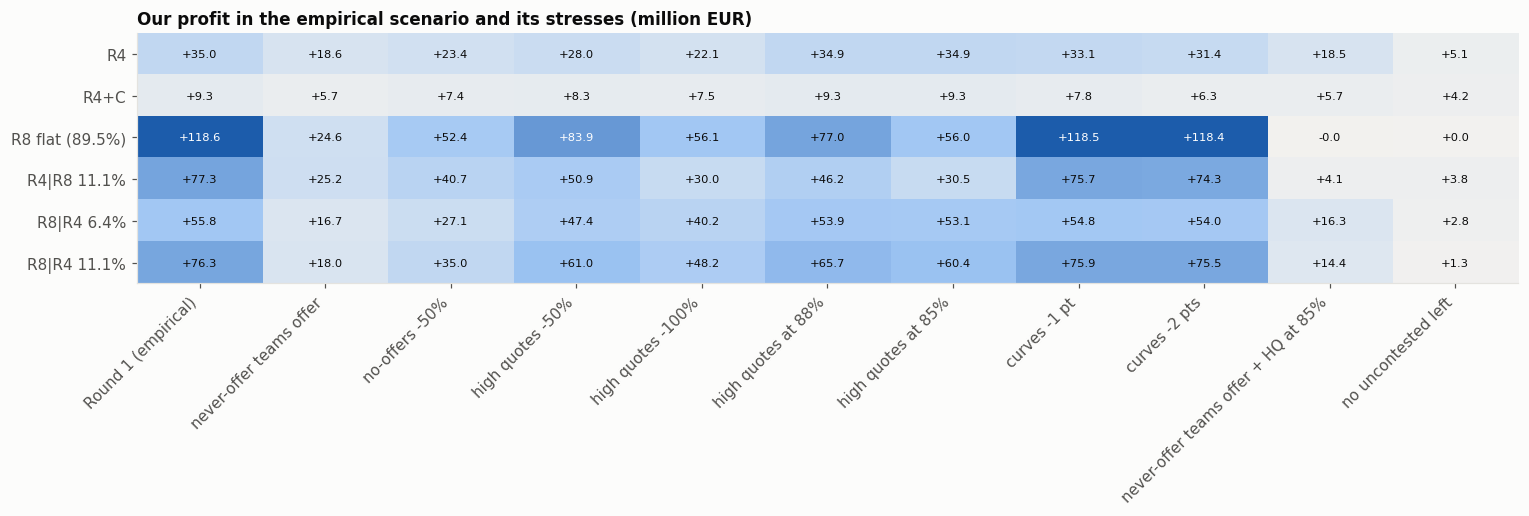

,Round 1 (empirical),never-offer teams offer,no-offers -50%,high quotes -50%,high quotes -100%,high quotes at 88%,high quotes at 85%,curves -1 pt,curves -2 pts,never-offer teams offer + HQ at 85%,no uncontested left
rule,,,,,,,,,,,
R4,+35.0,+18.6,+23.4,+28.0,+22.1,+34.9,+34.9,+33.1,+31.4,+18.5,+5.1
R4+C,+9.3,+5.7,+7.4,+8.3,+7.5,+9.3,+9.3,+7.8,+6.3,+5.7,+4.2
R8 flat (89.5%),+118.6,+24.6,+52.4,+83.9,+56.1,+77.0,+56.0,+118.5,+118.4,-0.0,+0.0
R4|R8 11.1%,+77.3,+25.2,+40.7,+50.9,+30.0,+46.2,+30.5,+75.7,+74.3,+4.1,+3.8
R8|R4 6.4%,+55.8,+16.7,+27.1,+47.4,+40.2,+53.9,+53.1,+54.8,+54.0,+16.3,+2.8
R8|R4 11.1%,+76.3,+18.0,+35.0,+61.0,+48.2,+65.7,+60.4,+75.9,+75.5,+14.4,+1.3


largest standard deviation over draws: 1.15M


In [11]:
SCENARIOS = {
    "Round 1 (empirical)": {},
    "never-offer teams offer": {"never_offer_team_offers": True},
    "no-offers -50%": {"keep_no_offer": 0.5},
    "high quotes -50%": {"keep_high_quote": 0.5},
    "high quotes -100%": {"keep_high_quote": 0.0},
    "high quotes at 88%": {"high_quote_rate": 0.88},
    "high quotes at 85%": {"high_quote_rate": 0.85},
    "curves -1 pt": {"curve_shift": 0.01},
    "curves -2 pts": {"curve_shift": 0.02},
    "never-offer teams offer + HQ at 85%": {"never_offer_team_offers": True, "high_quote_rate": 0.85},
    "no uncontested left": {"keep_no_offer": 0.0, "keep_high_quote": 0.0},
}
stress_mean, stress_sd = crr.score_scenarios(rates, data, data, SCENARIOS, seeds=range(5))

fig, ax = plt.subplots(figsize=(14, 4.8))
pp.plot_heatmap(stress_mean, ax, "Our profit in the empirical scenario and its stresses (million EUR)",
                scale=1e6, unit="million EUR", fmt="{:+.1f}")
fig.tight_layout()
save(fig, "fig25_empirical_scenario_stress.png")
plt.show()

display((stress_mean / 1e6).style.format("{:+.1f}"))
print(f"largest standard deviation over draws: {stress_sd.max().max() / 1e6:.2f}M")

**Stress tests of the empirical scenario** (5 draws each; our rates unchanged). A first look for
Part 11:

* **If the two never-offer teams start offering** (each slot's never-offer team now prices like the
  average curve team), **every high-quote rule collapses**:
  * R8 flat falls from €119M to **€25M**, and R8|R4 11.1% from €76M to **€18M**;
  * R4 itself falls from €35M to **€19M**, since a fifth of its Round 1 profit (€6.7M, Part 9) came
    from applicants with no competitor offer, and the riskier applicants it then faces bring the
    winner's curse with them.
  * **The best rule in that scenario is R4|R8 11.1%** (€25.2M), which quotes high only on risky
    applicants, where the uncontested pool comes from the high-quote and cutoff teams. **R8|R4, the
    "robust" hybrid of Part 9, falls below R4** (€18.0M and €16.7M): its high quote on safe applicants
    relied on exactly the 1/16 of applicants that the two never-offer teams leave alone.
  * This is the single most important unknown for Round 2.
* **Fewer no-offers or fewer high quotes hurt the high-quote rules roughly in proportion**: cutting
  each by half costs R8 €66M (no-offers) or €35M (high quotes).
* **The high-quote teams cutting to 85–88%** costs R8 €42–63M and R8|R4 11.1% €11–16M, but leaves
  R4 unchanged (€34.9M): R4 rarely quotes that high.
* **Curves 1–2 points cheaper** cost R4 €2–4M and barely touch R8, which wins nothing contested.
* **With no uncontested applicants left**, every rule earns **€0–5M**. The contested market is worth
  little: the uncontested borrowers that become contested are the riskier ones, and they bring their
  winner's curse with them. This is much worse for R4 than Part 9's simple stress, which assumed
  they would earn what contested applicants of the same band earned (€23.6M).

The scenario is now ready for Part 11: score candidate rules against `empirical_scenario` with its
stress knobs, giving the unstressed scenario the most weight.

## 7. Conclusions

**The competitors' rules**

1. **Each competitor slot is four teams, and their fingerprints identify them:** the decimals they
   rounded to, a fixed high quote, charm prices ending in 9. Counted in teams' worth, each slot
   splits into four teams in every risk band.
2. **One team in each slot never made an offer** (1A, 2A): exactly 25% of applicants, whatever the
   risk. They alone create the **6.25% of applicants with no competitor offer** among the safest.
3. **One team in each slot quotes a fixed high rate to risky applicants:** 91.99% from a predicted
   risk of about 7% (1B) and 97.89% from about 10% (2B). It prices a curve 2–3 points over break-even
   below that. Together with the refusals, these teams make up most of the risky uncontested pool.
4. **Lender 1 also has two cutoff teams** (1C, 1D). They stop lending to risky applicants: 1D
   refuses everyone above about 20%, and 1C keeps only a quarter of its offers there.
5. **The curve teams price safe applicants 1.4–3 points over break-even**, like our R4. Above 10%
   their margins diverge: 5 points (1D), 8–10 (1C), 7–20 rising (2C) and a 35–45-point step (2D).
6. **Our `p_own` adds nothing to their rates** once their own predicted risk is known ($c \approx 0$):
   they price on their own information, as expected.

**The empirical Round 2 scenario**

7. **Resampling real offers within (risk bin × default) reproduces Round 1 exactly enough**: every
   rule's profit within €0.2M. Conditioning on the default is essential (+€7.5M bias for R4
   without it).
8. **The high-quote strategy rests mostly on the two never-offer teams.** If they start offering,
   R8 falls from €119M to €25M and R8|R4 from €76M to €18M, against €19M for R4. Since it is a
   behaviour of two specific teams, possibly a submission problem, it may well not survive into
   Round 2.
9. **This reverses Part 9's choice of hybrid direction.** The safe uncontested applicants that made
   R8|R4 look robust exist only because of the never-offer teams. The risky uncontested pool comes
   from real pricing choices (high quotes, cutoffs). **R4|R8, a high quote on risky applicants only,
   is the best rule when the never-offer teams offer** (€25.2M) and stays strong otherwise (€77M).
10. **For Part 11:** choose the rule with the regret criterion across the empirical scenario and its
   stresses, especially **"never-offer teams offer"** and **"high quotes at 85%"**. The level of our
   own high quote should also be re-tuned per risk band against what the high-quote and cutoff teams
   leave.

**Limitations**

* **$\hat p$ is our forecast of each competitor's risk**, not their estimate. Every threshold and
  margin is blurred by their unseen signal, and the margin medians mix selection (a team that refuses
  risky applicants keeps the ones its signal says are safe).
* **Team assignment is exact only for some groups.** Lender 1's two 6-decimal teams cannot be told
  apart offer by offer (only by accounting), and ~14% of lender 2's charm group is the other
  4-decimal team.
* **The scenario reproduces Round 1 behaviour.** Teams that react to their own diagnostic files are
  covered only through the stress knobs, not modelled.